# Fitting a Track Through a Density Image

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GalacticDynamics/phasecurvefit/blob/main/docs/tutorials/density_fields.ipynb)

Sometimes the data are an image rather than a list of stars: a density map of a
stream from a simulation, or a probability map from a segmentation. Here we fit a
smooth track through such an image. Each pixel becomes a sample weighted by its value,
and three tools do the rest: per-sample `weights`, the `RidgeOrderer`, and the
autoencoder's `track_range`.

We draw the image around a curve we know, so we can measure how close each step
gets. [How density fields are fitted](../explanation/density-fields.md) explains why
each step works the way it does.

In [1]:
# On Colab, clone the repository, install the locked tutorial dependencies, and run
# from docs/tutorials. Elsewhere it does nothing: run from docs/tutorials with the
# `tutorials` extra.
import pathlib
import sys

repo = pathlib.Path("/content/phasecurvefit")
if "google.colab" in sys.modules:
    %pip install -q uv
    if not repo.exists():
        !git clone -q --depth 1 https://github.com/GalacticDynamics/phasecurvefit {repo}
    %cd {repo}
    !uv export -q --frozen --extra tutorials --no-dev --no-editable --no-hashes -o r.txt
    !uv pip install -q --system --python {sys.executable} -r r.txt
    %cd docs/tutorials

In [2]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

import phasecurvefit as pcf

## The image

The image is a soft mask around the curve $y = 1.5 \sin(0.6 x)$ for $x$ from 0 to
10, like a probability map from a segmentation. The weight is highest on the curve
and falls to zero at the edge of the region. The region's half-width grows from 0.3 at
the left end to 0.7 at the right end. One stretch is brighter than the rest and
another is fainter, and every pixel carries 30% noise.

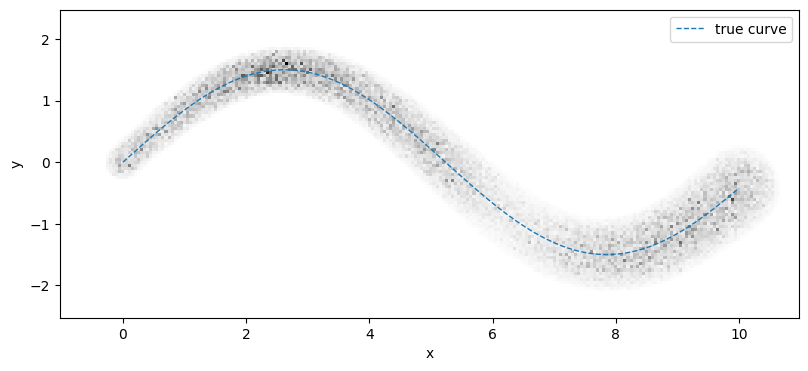

In [3]:
t = np.linspace(0.0, 10.0, 4000)
curve = np.stack([t, 1.5 * np.sin(0.6 * t)], axis=1)  # the true curve
s = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(curve, axis=0), axis=1))])

half_width = 0.3 + 0.4 * s / s[-1]  # widens along the curve
along = (
    1.0
    + 0.5 * np.exp(-0.5 * ((s - 0.25 * s[-1]) / 0.8) ** 2)  # a brighter stretch
    - 0.5 * np.exp(-0.5 * ((s - 0.65 * s[-1]) / 0.8) ** 2)  # and a fainter one
)

pix = 0.05
gx, gy = np.meshgrid(np.arange(-1.0, 11.0, pix), np.arange(-2.5, 2.5, pix))
d_px, i = cKDTree(curve).query(np.stack([gx.ravel(), gy.ravel()], axis=1))
across = np.clip(1.0 - (d_px / half_width[i]) ** 2, 0.0, None)  # 0 at the edge
noise = np.random.default_rng(0).lognormal(0.0, 0.3, d_px.size)
image = (along[i] * across * noise).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(gx, gy, image, cmap="Greys", shading="auto")
ax.plot(*curve.T, c="C0", lw=1, ls="--", label="true curve")
ax.set(aspect="equal", xlabel="x", ylabel="y")
ax.legend(loc="upper right");

## Pixels as weighted samples

Every pixel with a positive value becomes a sample, weighted by that value. An image
has no velocities, so we set them to zero. The orderers used below don't read them,
and without them the direction of the ordering, which end $\gamma$ starts from, is
arbitrary.

In [4]:
keep = image.ravel() > 0
pos = {"x": jnp.asarray(gx.ravel()[keep]), "y": jnp.asarray(gy.ravel()[keep])}
vel = jax.tree.map(jnp.zeros_like, pos)
weights = jnp.asarray(image.ravel()[keep])
print(f"{int(keep.sum())} pixels")


def summarize(track):
    """Mean and max distance from a track to the true curve, and its end errors."""
    xy = np.stack([np.asarray(track["x"]), np.asarray(track["y"])], axis=1)
    d = cKDTree(curve).query(xy)[0]
    ends = xy[[0, -1]]
    if np.linalg.norm(ends[0] - curve[0]) > np.linalg.norm(ends[0] - curve[-1]):
        ends = ends[::-1]  # the ordering may run right to left
    left, right = np.linalg.norm(ends - curve[[0, -1]], axis=1)
    return (
        f"mean {d.mean():.3f}, max {d.max():.3f}, "
        f"ends off by {left:.2f} and {right:.2f}"
    )

5053 pixels


## Order the pixels

We order the pixels two ways. `pcf.order` with no orderer runs the default pipeline:
a minimum-spanning-tree (MST) backbone refined by a self-organizing map (SOM). The
`RidgeOrderer` builds its backbone along the ridge of the weighted density instead.
It smooths the samples into a density, finds the two ends of the dense core, and
follows the ridge between them. Its smoothing width, `bandwidth`, is estimated from
the data by default. We chain a SOM after it, with a position-only metric because the
velocities are zero.

default pipeline: mean 0.035, max 0.083, ends off by 0.90 and 0.06
ridge, then SOM:  mean 0.028, max 0.192, ends off by 0.39 and 0.19


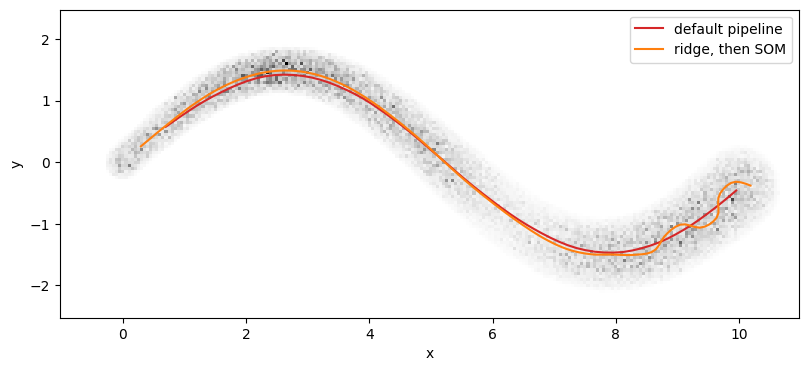

In [5]:
default = pcf.order(pos, vel, weights=weights)

chain = pcf.orderers.RidgeOrderer() | pcf.orderers.SOMOrderer(
    n_prototypes=30, metric=pcf.metrics.SpatialDistanceMetric(), n_epochs=30
)
ordering = pcf.order(pos, vel, chain, weights=weights)

print("default pipeline:", summarize(default.backbone))
print("ridge, then SOM: ", summarize(ordering.backbone))

fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(gx, gy, image, cmap="Greys", shading="auto")
ax.plot(
    default.backbone["x"],
    default.backbone["y"],
    c="C3",
    lw=1.5,
    label="default pipeline",
)
ax.plot(
    ordering.backbone["x"],
    ordering.backbone["y"],
    c="C1",
    lw=1.5,
    label="ridge, then SOM",
)
ax.set(aspect="equal", xlabel="x", ylabel="y")
ax.legend(loc="upper right");

Both backbones follow the middle of the stream. The default one stops well short of
the narrow left end. The ridge-then-SOM one gets closer to that end, but it wiggles
where the stream is widest and noisiest: its 30 prototypes sit closer together than
the stream is wide there, so they follow clumps of noise. Neither backbone is the
final track. The autoencoder below smooths the wiggles and finds the ends from the
pixels themselves.

## Fit the track

The autoencoder gives every pixel an ordering coordinate $\gamma$ and fits a smooth
track. It reads the weights from the ordering result. Two training settings matter
for a stream this wide, compared with a thin stream of stars:

- `freeze_encoder_final_training=True`. In the last, joint phase, the reconstruction
  loss can lower itself by letting $\gamma$ encode position across the stream, which
  bends the track into loops on the curves. Freezing the encoder keeps $\gamma$ an
  along-track coordinate.
- `batch_size=1000`. The spread of pixels across the stream is much larger than the
  error the decoder has left to fix, so small batches keep it jittering around the
  track instead of settling on it.

We draw the track over `track_range`, which stops where the pixels thin out at each
end, rather than over all of `gamma_range`. To see how much the ordering matters, we
train one track from each ordering.

track from ridge ordering, track_range:   mean 0.018, max 0.333, ends off by 0.05 and 0.33
track from ridge ordering, gamma_range:   mean 0.034, max 0.603, ends off by 0.32 and 0.60
track from default ordering, track_range: mean 0.021, max 0.373, ends off by 0.06 and 0.37


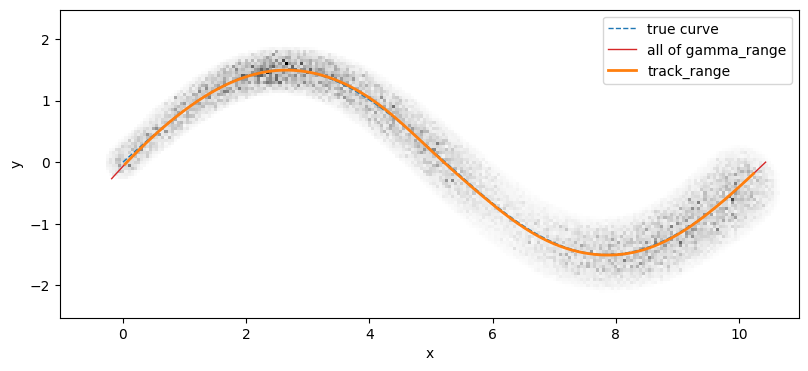

In [6]:
config = pcf.nn.TrainingConfig(
    freeze_encoder_final_training=True, batch_size=1000, show_pbar=False
)


def fit(ordering, key):
    model = pcf.nn.PathAutoencoder.make(
        normalizer=pcf.nn.StandardScalerNormalizer(pos, vel),
        gamma_range=ordering.gamma_range,
        key=jax.random.key(key),
    )
    fitted, _, _ = pcf.nn.train_autoencoder(
        model, ordering, config=config, key=jax.random.key(key + 1)
    )
    return fitted


fitted = fit(ordering, 0)
fitted_default = fit(default, 0)
track = fitted(jnp.linspace(*fitted.track_range, 500))
full = fitted(jnp.linspace(*fitted.gamma_range, 500))
track_default = fitted_default(jnp.linspace(*fitted_default.track_range, 500))

print("track from ridge ordering, track_range:  ", summarize(track))
print("track from ridge ordering, gamma_range:  ", summarize(full))
print("track from default ordering, track_range:", summarize(track_default))

fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(gx, gy, image, cmap="Greys", shading="auto")
ax.plot(*curve.T, c="C0", lw=1, ls="--", label="true curve")
ax.plot(full["x"], full["y"], c="C3", lw=1, label="all of gamma_range")
ax.plot(track["x"], track["y"], c="C1", lw=2, label="track_range")
ax.set(aspect="equal", xlabel="x", ylabel="y")
ax.legend(loc="upper right");

The track lies within a few hundredths of the curve along its length, and the two
orderings give nearly the same track, so on this image the autoencoder makes up for
the differences between them. At the narrow left end the track stops close to the true
end. Drawn over all of `gamma_range` it would overshoot both ends.

At the wide right end the track stops partway into the soft cap past the end of the
curve. This mask was made by thickening a curve, so its cap holds real weight, and the
image alone can't tell a short curve with a cap from a longer, blurrier one.
[How density fields are fitted](../explanation/density-fields.md#where-the-track-ends)
says more about that.

## Where the ridge matters

The ordering matters more on a uniform segmentation mask, where every pixel in the
region has the same weight, and on a blurred image of a thin line. On these, the
default pipeline's backbone cuts inside the bends and misses the ends, and on the
blurred line it hooks back on itself at the left end. The ridge follows the centre
line from end to end:

uniform mask, radius 0.5, default: mean 0.030, max 0.067, ends off by 0.31 and 0.32


uniform mask, radius 0.5, ridge, then SOM: mean 0.007, max 0.045, ends off by 0.04 and 0.04


blurred line, sigma 0.25, default: mean 0.058, max 0.129, ends off by 1.11 and 0.35


blurred line, sigma 0.25, ridge, then SOM: mean 0.004, max 0.007, ends off by 0.01 and 0.01


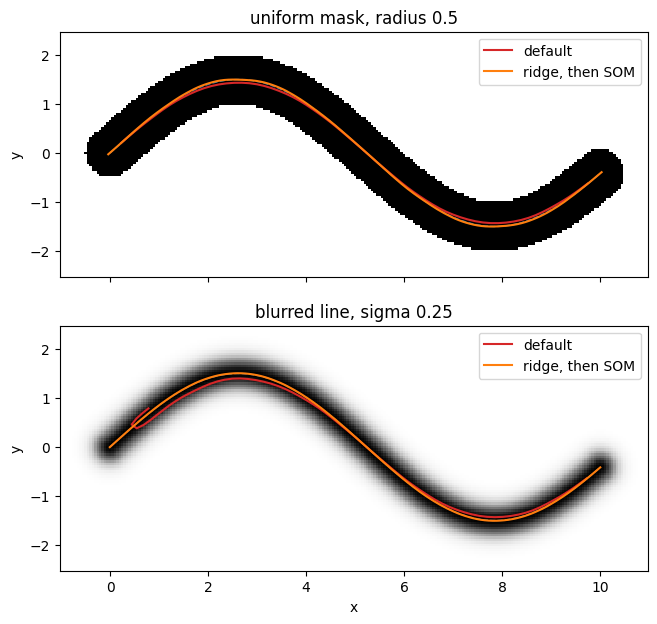

In [7]:
def order_image(img, orderer):
    keep = img.ravel() > 0
    p = {"x": jnp.asarray(gx.ravel()[keep]), "y": jnp.asarray(gy.ravel()[keep])}
    v = jax.tree.map(jnp.zeros_like, p)
    return pcf.order(p, v, orderer, weights=jnp.asarray(img.ravel()[keep]))


d_img = d_px.reshape(gx.shape)  # each pixel's distance to the curve
images = {
    "uniform mask, radius 0.5": (d_img <= 0.5).astype(float),
    "blurred line, sigma 0.25": np.exp(-0.5 * (d_img / 0.25) ** 2) * (d_img < 1.0),
}
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (name, img) in zip(axs, images.items(), strict=True):
    ax.pcolormesh(gx, gy, img, cmap="Greys", shading="auto")
    ax.plot(*curve.T, c="C0", lw=1, ls="--")
    for label, orderer, color in [
        ("default", None, "C3"),
        ("ridge, then SOM", chain, "C1"),
    ]:
        res = order_image(img, orderer)
        print(f"{name}, {label}: {summarize(res.backbone)}")
        ax.plot(res.backbone["x"], res.backbone["y"], c=color, lw=1.5, label=label)
    ax.set(aspect="equal", ylabel="y", title=name)
    ax.legend(loc="upper right")
axs[-1].set_xlabel("x");

## Summary

- Each pixel is a sample weighted by its value: pass the image's values as `weights`.
- Order with `RidgeOrderer() | SOMOrderer(...)`. On uniform masks and blurred lines it
  follows the centre line where the default pipeline drifts and misses the ends.
- Train with `freeze_encoder_final_training=True` and large batches, and draw the
  track over `track_range`.

[How density fields are fitted](../explanation/density-fields.md) explains each of
these choices.